# Word2Vec Skip-gram from scratch (NumPy)

This notebook implements the `WORD2VEC-SKIPGRAM(Corpus, c, d, η, T)` pseudocode line by line, using a **full softmax** exactly as written.

| Symbol | Meaning |
|---|---|
| `c` | context window size |
| `d` | embedding dimension |
| `η` | learning rate |
| `T` | number of epochs |

Run the cells top to bottom (**Runtime → Run all**).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

np.random.seed(42)
random.seed(42)

## Corpus
A small toy corpus with clear topics (royalty, animals, fruit) so you can see related words cluster together. Swap in your own sentences any time.

In [2]:
corpus = [
    "the king rules the kingdom",
    "the queen rules the kingdom",
    "the king and the queen live in the palace",
    "a prince is the son of a king",
    "a princess is the daughter of a queen",
    "the prince and the princess live in the palace",
    "the dog chases the cat",
    "the cat chases the mouse",
    "a dog is a loyal pet",
    "a cat is a lazy pet",
    "the dog and the cat play in the garden",
    "the mouse hides from the cat",
    "i eat an apple every day",
    "i eat a banana every morning",
    "an apple is a sweet fruit",
    "a banana is a yellow fruit",
    "an orange is a juicy fruit",
    "i eat an orange and a banana",
]

# Tokenize: lowercase + split on whitespace
sentences = [s.lower().split() for s in corpus]
print(sentences[:3])

[['the', 'king', 'rules', 'the', 'kingdom'], ['the', 'queen', 'rules', 'the', 'kingdom'], ['the', 'king', 'and', 'the', 'queen', 'live', 'in', 'the', 'palace']]


## Step 1 — Build vocabulary V

In [3]:
vocab = sorted(set(w for s in sentences for w in s))
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)
print("Vocabulary size |V| =", V)

Vocabulary size |V| = 40


## Steps 2 & 3 — Initialize E and W randomly
- `E` has shape `|V| × d` (one input embedding per word)
- `W` has shape `d × |V|` (one output vector per word, stored as columns)

In [4]:
def init_params(V, d):
    E = np.random.uniform(-0.5, 0.5, (V, d)) / d   # input embeddings
    W = np.random.uniform(-0.5, 0.5, (d, V)) / d   # output weights
    return E, W

## Step 4 — Generate training pairs (center, context)

In [5]:
def generate_pairs(sentences, c):
    pairs = []
    for sentence in sentences:                          # For each sentence
        for i, w in enumerate(sentence):                # For each word w at position i
            lo, hi = max(0, i - c), min(len(sentence), i + c + 1)
            for j in range(lo, hi):                     # For each context position j within window c
                if i != j:                              # If i != j
                    pairs.append((word2idx[w], word2idx[sentence[j]]))  # Add pair
    return pairs

pairs = generate_pairs(sentences, c=2)
print("Number of training pairs:", len(pairs))
print("First 5 pairs:", [(idx2word[a], idx2word[b]) for a, b in pairs[:5]])

Number of training pairs: 364
First 5 pairs: [('the', 'king'), ('the', 'rules'), ('king', 'the'), ('king', 'rules'), ('king', 'the')]


## Step 5 — Training loop (forward → loss → backprop → update)

In [6]:
def softmax(x):
    x = x - np.max(x)          # subtract max for numerical stability
    e = np.exp(x)
    return e / e.sum()


def word2vec_skipgram(sentences, c=2, d=10, eta=0.05, T=100, verbose=True):
    E, W = init_params(V, d)                       # Steps 2 & 3
    pairs = generate_pairs(sentences, c)           # Step 4
    losses = []

    for epoch in range(1, T + 1):                  # Step 5: For epoch = 1 to T
        random.shuffle(pairs)                      # Shuffle training pairs
        total_loss = 0.0

        for center, context in pairs:              # For each pair (center, context)
            # ---- Forward pass ----
            h = E[center]                          # shape (d,)
            scores = h @ W                         # shape (|V|,)
            probs = softmax(scores)                # shape (|V|,)

            # ---- Compute loss ----
            loss = -np.log(probs[context] + 1e-12)
            total_loss += loss

            # ---- Backpropagation ----
            error = probs.copy()                   # error = probabilities
            error[context] -= 1                    # error[context] -= 1

            gradient_W = np.outer(h, error)        # h^T × error   -> shape (d, |V|)
            gradient_h = W @ error                 # W × error     -> shape (d,)

            # ---- Update parameters ----
            W -= eta * gradient_W
            E[center] -= eta * gradient_h

        avg = total_loss / len(pairs)
        losses.append(avg)
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"Epoch {epoch:3d} | avg loss = {avg:.4f}")

    return E, W, losses                            # Step 6: Return E

## Train

Epoch   1 | avg loss = 3.6887
Epoch  10 | avg loss = 2.8783
Epoch  20 | avg loss = 2.5310
Epoch  30 | avg loss = 2.3632
Epoch  40 | avg loss = 2.2860
Epoch  50 | avg loss = 2.2645
Epoch  60 | avg loss = 2.2462
Epoch  70 | avg loss = 2.2443
Epoch  80 | avg loss = 2.2534
Epoch  90 | avg loss = 2.2492
Epoch 100 | avg loss = 2.2450


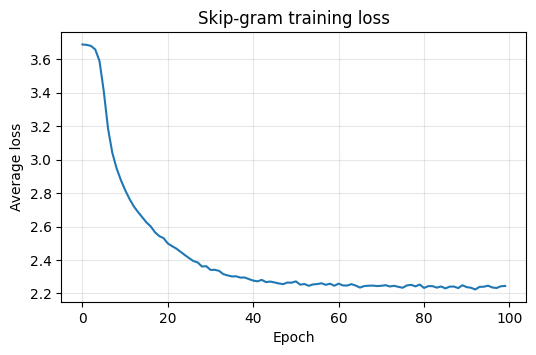

In [7]:
E, W, losses = word2vec_skipgram(sentences, c=2, d=10, eta=0.05, T=100)

plt.figure(figsize=(6, 3.5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Average loss")
plt.title("Skip-gram training loss")
plt.grid(alpha=0.3)
plt.show()

## Check the embeddings: nearest neighbours by cosine similarity

In [8]:
def most_similar(word, E, topn=5):
    v = E[word2idx[word]]
    norms = np.linalg.norm(E, axis=1) * np.linalg.norm(v) + 1e-12
    sims = (E @ v) / norms
    best = np.argsort(-sims)
    return [(idx2word[i], round(float(sims[i]), 3)) for i in best if i != word2idx[word]][:topn]

for w in ["king", "queen", "dog", "cat", "apple", "banana"]:
    print(f"{w:7s} ->", most_similar(w, E))

king    -> [('kingdom', 0.856), ('queen', 0.832), ('son', 0.756), ('prince', 0.756), ('daughter', 0.746)]
queen   -> [('king', 0.832), ('princess', 0.779), ('kingdom', 0.72), ('garden', 0.643), ('palace', 0.637)]
dog     -> [('prince', 0.871), ('cat', 0.869), ('mouse', 0.677), ('princess', 0.637), ('orange', 0.626)]
cat     -> [('dog', 0.869), ('princess', 0.738), ('prince', 0.73), ('mouse', 0.657), ('palace', 0.597)]
apple   -> [('orange', 0.792), ('i', 0.726), ('banana', 0.602), ('lazy', 0.587), ('loyal', 0.564)]
banana  -> [('orange', 0.67), ('i', 0.65), ('apple', 0.602), ('yellow', 0.559), ('sweet', 0.546)]


## Visualize the embeddings in 2D (PCA)

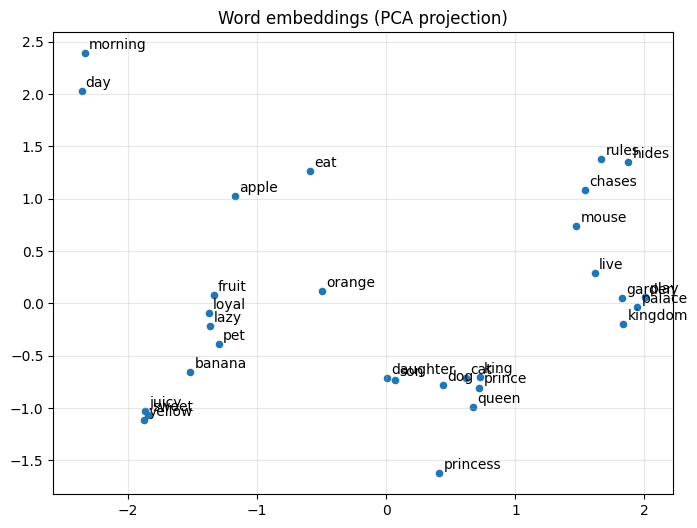

In [9]:
def pca_2d(X):
    Xc = X - X.mean(axis=0)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T

stopwords = {"the", "a", "an", "is", "and", "in", "of", "i", "from", "every"}
words = [w for w in vocab if w not in stopwords]
coords = pca_2d(E[[word2idx[w] for w in words]])

plt.figure(figsize=(8, 6))
plt.scatter(coords[:, 0], coords[:, 1], s=20)
for (x, y), w in zip(coords, words):
    plt.annotate(w, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=10)
plt.title("Word embeddings (PCA projection)")
plt.grid(alpha=0.3)
plt.show()